<a href="https://colab.research.google.com/github/julia-zhmurko/JuliaZhmurko-ML/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D1%96_%D1%80%D0%BE%D0%B1%D0%BE%D1%82%D0%B8/%D0%96%D0%BC%D1%83%D1%80%D0%BA%D0%BE_%D0%AE%D0%BB%D1%96%D1%8F_%D0%A4%D0%86%D0%A2_4_10_%D0%9B%D0%A0_6_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D0%B0_%D0%BF%D0%B5%D1%80%D0%B5%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_26_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

**Автор:** студентка групи ФІТ 4-10 Жмурко Юлія Андріївна

**Була присутня на парі (21.10.2026)**

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

###**Пояснення:**

Імпортуємо необхідні бібліотеки для роботи з даними, виконання числових обчислень та побудови графіків.

Бібліотеку `pandas` використаємо для обробки та аналізу даних, `numpy` – для числових обчислень, `matplotlib.pyplot` та `seaborn` – для візуалізації результатів.

Модуль `files` із `google.colab` забезпечить завантаження файлу датасету, а `os` – роботу з файлами та шляхами до них.

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [2]:
# Завантаження файлу
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv


In [3]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


###**Характеристики датасету:**

**gender** – стать пацієнта (Female – жіноча, Male – чоловіча, Other – інша).

**age** – вік пацієнта в роках.

**hypertension** – наявність артеріальної гіпертензії (0 – відсутня, 1 – наявна).

**heart_disease** – наявність серцевих захворювань (0 – відсутні, 1 – наявні).

**smoking_history** – історія куріння пацієнта:
- never – ніколи не курив;
- former – курив раніше;
- current – курить зараз;
- not current – наразі не курить;
- ever – курив протягом життя;
- No Info – інформація відсутня.

**bmi** – індекс маси тіла (Body Mass Index), який характеризує співвідношення маси тіла та зросту пацієнта, кг/м².

**HbA1c_level** – рівень глікованого гемоглобіну HbA1c (%), який відображає середній рівень глюкози в крові приблизно за останні 2–3 місяці.

**blood_glucose_level** – рівень глюкози в крові пацієнта.

**diabetes** – наявність цукрового діабету (0 – діабет відсутній, 1 – діабет наявний). Цільова змінна, значення якої необхідно прогнозувати за допомогою моделей класифікації.

###**Пояснення:**

Завантажимо датасет `diabetes_prediction_dataset.csv` із комп’ютера до середовища `Google Colab` за допомогою методу `files.upload()`.

Далі за допомогою функції `pd.read_csv()` зчитаємо дані з CSV-файлу та збережемо їх у DataFrame `df`.

Виведемо вміст датасету для ознайомлення з його структурою.

У результаті отримали набір даних, який містить 100 000 записів та 9 стовпців, що включають інформацію про стать, вік, наявність гіпертонії та серцевих захворювань, історію куріння, індекс маси тіла (BMI), рівень HbA1c, рівень глюкози в крові та наявність діабету (diabetes).

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [4]:
import kagglehub

path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [5]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


###**Пояснення:**

Завантажимо датасет `diabetes-prediction-dataset` безпосередньо з платформи `Kaggle` до середовища `Google Colab` за допомогою бібліотеки `kagglehub`.

Використаємо метод `kagglehub.dataset_download()`, який завантажує набір даних та повертає шлях до каталогу з його файлами.

Отриманий шлях збережемо у змінній `path` та виведемо на екран.

Далі за допомогою функції `os.path.join()` сформуємо повний шлях до файлу `diabetes_prediction_dataset.csv`.

Використовуючи функцію `pd.read_csv()`, зчитаємо дані з CSV-файлу та збережемо їх у DataFrame `df`.

Виведемо вміст датасету для перевірки правильності завантаження.

У результаті отримали набір даних, що містить 100 000 записів та 9 стовпців, які включають демографічні й медичні характеристики пацієнтів та цільову змінну `diabetes`.

Вивести інформацію про датасет

In [6]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


###**Пояснення:**

За допомогою методу `df.info()` виведемо загальну інформацію про структуру датасету, зокрема кількість записів та стовпців, типи даних і кількість непорожніх значень для кожної ознаки.

У результаті встановлено, що датасет містить 100 000 записів та 9 стовпців, з яких 2 мають тип даних `object` (категоріальні ознаки), 3 – `float64` (дійсні числа) та 4 – `int64` (цілі числа).

Усі стовпці містять по 100 000 непорожніх значень, що свідчить про відсутність пропущених значень `NaN`.

Провести дослідження категоріальних ознак

In [7]:
# TODO: підрахуйте частоти категорій у gender.

df['gender'].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


###**Пояснення:**

За допомогою методу `value_counts()` підрахуємо частоту категорій у стовпці `gender`, який містить інформацію про стать пацієнтів.

У результаті встановлено, що серед 100 000 записів датасету 58 552 (58,55%) належать до категорії `Female` (жіноча стать), 41 430 (41,43%) – до категорії `Male` (чоловіча стать) та 18 (0,02%) – до категорії `Other` (інша стать).

Отже, у наборі даних переважають пацієнти жіночої статі, тоді як категорія `Other` представлена найменшою кількістю записів.

In [8]:
# TODO: підрахуйте частоти категорій у smoking_history.

df['smoking_history'].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


###**Пояснення:**

За допомогою методу `value_counts()` підрахуємо частоту категорій у стовпці `smoking_history`, який містить інформацію про історію куріння пацієнтів.

У результаті встановлено, що серед 100 000 записів датасету 35 816 (35,82%) належать до категорії `No Info` (інформація відсутня), 35 095 (35,10%) – `never` (ніколи не курили), 9 352 (9,35%) – `former` (курили раніше), 9 286 (9,29%) – `current` (курять зараз), 6 447 (6,45%) – `not current` (наразі не курять) та 4 004 (4,00%) – `ever` (курили протягом життя).

Отже, у наборі даних найбільше записів належить до категорій `No Info` та `never`, тоді як найменше – до категорії `ever`.

In [9]:
# TODO: df

df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


###**Пояснення:**

Виведемо вміст DataFrame `df` для перегляду структури та значень датасету після виконання попередніх операцій.

У результаті отримали таблицю, яка містить 100 000 записів та 9 стовпців із демографічними й медичними характеристиками пацієнтів, а також цільовою змінною `diabetes`.

Відображено перші та останні п'ять записів набору даних, що дозволяє ознайомитися зі значеннями ознак і перевірити правильність представлення даних.

Вивести типи даних

In [10]:
# TODO: df.dtypes

df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


###**Пояснення:**

За допомогою атрибута `df.dtypes` виведемо типи даних усіх стовпців датасету, що дозволить визначити формат представлення кожної ознаки.

У результаті встановлено, що 2 стовпці мають тип даних `object` (`gender`, `smoking_history`), 3 – `float64` (`age`, `bmi`, `HbA1c_level`) та 4 – `int64` (`hypertension`, `heart_disease`, `blood_glucose_level`, `diabetes`).

Отримані результати підтверджують наявність у датасеті як числових, так і категоріальних ознак.

Дослідити цільову змінну: перевірити баланс класів

In [11]:
# TODO: df['diabetes'].value_counts()

df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


###**Пояснення:**

За допомогою методу `value_counts()` дослідимо розподіл класів цільової змінної `diabetes`, яка характеризує наявність або відсутність цукрового діабету в пацієнтів.

У результаті встановлено, що серед 100 000 записів датасету 91 500 (91,5%) належать до класу 0 (діабет відсутній), а 8 500 (8,5%) – до класу 1 (діабет наявний).

Висновок: визначте за результатом, чи є дисбаланс класів.

###**Висновок:**

Отримані результати свідчать про наявність значного дисбалансу класів у датасеті, оскільки кількість пацієнтів без діабету приблизно в 10,8 раза перевищує кількість пацієнтів із діабетом.

Такий дисбаланс необхідно враховувати під час навчання та оцінювання моделей класифікації, оскільки моделі можуть надавати перевагу прогнозуванню більшості класу (0).

Тому для оцінювання якості моделей доцільно використовувати не лише `accuracy`, а й `precision`, `recall`, `F1-score` та матрицю плутанини.

Перевірити наявність пропущених даних


In [12]:
# TODO: df.isnull().sum()

df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


###**Пояснення:**

За допомогою методів `isnull()` та `sum()` перевіримо наявність пропущених значень у кожному стовпці датасету.

Метод `isnull()` використаємо для визначення відсутніх значень (`NaN`), а метод `sum()` – для підрахунку їх кількості за кожною ознакою.

У результаті встановлено, що всі 9 стовпців датасету містять 0 пропущених значень, тобто відсутні значення `NaN` у наборі даних не виявлено.

Наявність дублікатів


In [13]:
# TODO: df.duplicated().sum()

df.duplicated().sum()

np.int64(3854)

###**Пояснення:**

За допомогою методів `duplicated()` та `sum()` перевіримо наявність дублікатів у датасеті.

Метод `duplicated()` використаємо для виявлення рядків, значення яких повністю збігаються за всіма стовпцями, а метод `sum()` – для підрахунку загальної кількості таких повторень.

У результаті встановлено, що серед 100 000 записів датасету 3 854 (3,85%) є дублікатами, тобто повторюють значення інших записів за всіма ознаками.

Отже, кількість рядків без повторень становить 96 146.

Видалити дублікати

In [14]:
# TODO: df.drop_duplicates(inplace=True)

df.drop_duplicates(inplace = True)

In [15]:
# TODO: df

df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


###**Пояснення:**

За допомогою методу `drop_duplicates()` виконаємо видалення дублікатів із датасету, використовуючи параметр `inplace=True` для збереження змін безпосередньо в DataFrame `df`.

Далі виведемо оновлений вміст датасету для перевірки результатів видалення повторюваних записів.

У результаті встановлено, що після видалення 3 854 дублікатів (3,85%) кількість записів у датасеті зменшилася зі 100 000 до 96 146, тоді як кількість стовпців залишилася незмінною – 9.

Ще раз перевірити баланс цільової змінної

In [16]:
# TODO: df['diabetes'].value_counts()

df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


###**Пояснення:**

За допомогою методу `value_counts()` повторно дослідимо розподіл класів цільової змінної `diabetes` після видалення дублікатів із датасету.

Підрахуємо кількість записів для кожного класу та порівняємо отримані результати з початковим розподілом.

У результаті встановлено, що серед 96 146 записів оновленого датасету 87 664 (91,18%) належать до класу 0 (діабет відсутній), а 8 482 (8,82%) – до класу 1 (діабет наявний).

Отримані результати свідчать про те, що після видалення 3 854 дублікатів дисбаланс класів у датасеті зберігся.

Кількість записів класу 0 зменшилася на 3 836, тоді як класу 1 – лише на 18.

Частка пацієнтів із діабетом незначно збільшилася з 8,5% до 8,82%, проте кількість записів без діабету залишається приблизно в 10,3 раза більшою.

Побудувати гістограму для цільової змінної


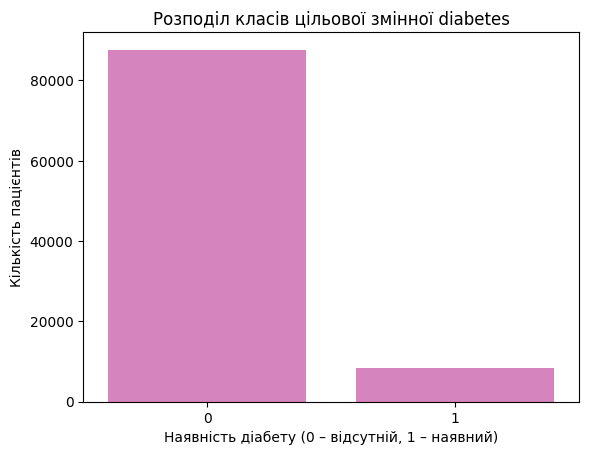

In [17]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')

sns.countplot(x = 'diabetes', data = df, color = 'tab:pink')
plt.title('Розподіл класів цільової змінної diabetes')
plt.xlabel('Наявність діабету (0 – відсутній, 1 – наявний)')
plt.ylabel('Кількість пацієнтів')
plt.show()

###**Пояснення:**

За допомогою функції `sns.countplot()` побудуємо гістограму розподілу класів цільової змінної `diabetes`, яка дозволить наочно порівняти кількість пацієнтів із діабетом та без нього.

На осі `X` відобразимо значення цільової змінної (0 – діабет відсутній, 1 – діабет наявний), а на осі `Y` – кількість пацієнтів.

Для оформлення графіка використаємо функції `plt.title()`, `plt.xlabel()` та `plt.ylabel()`, а для встановлення кольору стовпців – параметр `color='tab:pink'`.

У результаті отримали гістограму, на якій спостерігається значне переважання класу 0 (87 664 записи, або 91,18%) над класом 1 (8 482 записи, або 8,82%).

Побудована гістограма підтверджує наявність значного дисбалансу класів цільової змінної `diabetes`.

Кількість пацієнтів без діабету приблизно в 10,3 раза перевищує кількість пацієнтів із діабетом.

Переглянути описові статистики **навчальної вибірки**

In [18]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

###**Пояснення:**

Імпортуємо необхідні класи та функції для підготовки даних, побудови й оцінювання моделей класифікації.

Із бібліотеки `sklearn` імпортуємо класи `LogisticRegression`, `RidgeClassifier`, `SGDClassifier` та `SVC` для навчання відповідних моделей класифікації.

Клас `StandardScaler` використаємо для стандартизації числових ознак, а функцію `train_test_split()` – для розбиття датасету на навчальну та тестову вибірки.

Для оцінювання якості моделей використаємо функції `classification_report()` та `confusion_matrix()`, які дозволять отримати звіти класифікації та матриці плутанини.

Також імпортуємо метод `SMOTE` для можливого балансування класів навчальної вибірки.

In [19]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.

X = df.drop('diabetes', axis = 1)
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify = y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (76916, 8)
X_test: (19230, 8)
y_train: (76916,)
y_test: (19230,)


###**Пояснення:**

Розділимо датасет на вхідні ознаки `X` та цільову змінну `y`, де `X` міститиме всі характеристики пацієнтів, крім стовпця `diabetes`, а `y` – значення цільової змінної, які необхідно прогнозувати.

Далі за допомогою функції `train_test_split()` виконаємо розбиття даних на навчальну (`X_train`, `y_train`) та тестову (`X_test`, `y_test`) вибірки у співвідношенні 80/20.

Для цього використаємо параметр `test_size=0.2`, а `random_state=42` забезпечить відтворюваність результатів розбиття.

Також встановимо параметр `stratify=y`, який дозволить зберегти приблизне співвідношення класів цільової змінної в обох вибірках.

У результаті розбиття датасету сформовано навчальну вибірку, яка містить 76 916 записів (80%), та тестову вибірку, яка містить 19 230 записів (20%).

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [20]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).

X_train = pd.get_dummies(X_train, columns = ['gender', 'smoking_history'], dtype = int)
X_test = pd.get_dummies(X_test, columns = ['gender', 'smoking_history'], dtype = int)
X_test = X_test.reindex(columns = X_train.columns, fill_value = 0)

print ("Ознак після кодування:", X_train.shape[1])

Ознак після кодування: 15


###**Пояснення:**

За допомогою функції `pd.get_dummies()` виконаємо кодування категоріальних ознак `gender` та `smoking_history` окремо для навчальної та тестової вибірок.

Для представлення категорій у вигляді числових значень 0 та 1 використаємо параметр `dtype=int`.

Далі за допомогою методу `reindex()` узгодимо стовпці тестової вибірки `X_test` зі стовпцями навчальної вибірки `X_train`, використовуючи параметри `columns=X_train.columns` та `fill_value=0`.

У результаті після кодування кількість вхідних ознак збільшилася з 8 до 15, оскільки категоріальні змінні `gender` та `smoking_history` було перетворено на окремі бінарні стовпці.

In [21]:
# TODO: виведіть статистики опису X_train.

X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


###**Пояснення:**

За допомогою методу `describe()` виведемо описові статистики всіх 15 ознак навчальної вибірки `X_train`, зокрема кількість значень, середнє арифметичне, стандартне відхилення, мінімальні та максимальні значення, а також квартилі розподілу.

У результаті встановлено, що навчальна вибірка містить 76 916 записів.

Середній вік пацієнтів становить приблизно 41,76 року, середній індекс маси тіла (`bmi`) – 27,31, середній рівень глікованого гемоглобіну (`HbA1c_level`) – 5,53, а середній рівень глюкози в крові (`blood_glucose_level`) – 138,11.

Також визначено, що значення віку змінюються від 0,08 до 80 років, індексу маси тіла – від 10,01 до 95,22, рівня HbA1c – від 3,5 до 9,0, а рівня глюкози в крові – від 80 до 300.

Для закодованих категоріальних ознак середні значення відображають частку записів, які належать до відповідних категорій.

Наприклад, частка пацієнтів жіночої статі (`gender_Female`) у навчальній вибірці становить приблизно 58,27%, чоловічої (`gender_Male`) – 41,71%, а категорії `Other` (`gender_Other`) – 0,02%.

Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [22]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).

print("Кореляція ознак із цільовою змінною diabetes:")
X_train.corrwith(y_train).sort_values(ascending = False)

Кореляція ознак із цільовою змінною diabetes:


,0
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725
smoking_history_ever,0.020899


###**Пояснення:**

За допомогою методу `corrwith()` обчислимо коефіцієнти кореляції між ознаками навчальної вибірки `X_train` та цільовою змінною `y_train` (`diabetes`).

Для впорядкування отриманих коефіцієнтів за спаданням використаємо метод `sort_values()` із параметром `ascending=False`.

Найбільший додатний зв'язок із наявністю діабету мають рівень глюкози в крові (`blood_glucose_level`) та рівень глікованого гемоглобіну (`HbA1c_level`).

Їхні коефіцієнти кореляції становлять приблизно 0,42 та 0,41 відповідно, що свідчить про помірний додатний лінійний зв'язок із цільовою змінною.

Ознаки `age`, `bmi`, `hypertension` та `heart_disease` мають слабший додатний зв'язок із наявністю діабету.

Серед від'ємних кореляцій найбільше за абсолютним значенням виділяється `smoking_history_No Info` (−0,113), тоді як решта категоріальних ознак мають переважно дуже слабкий зв'язок із цільовою змінною.

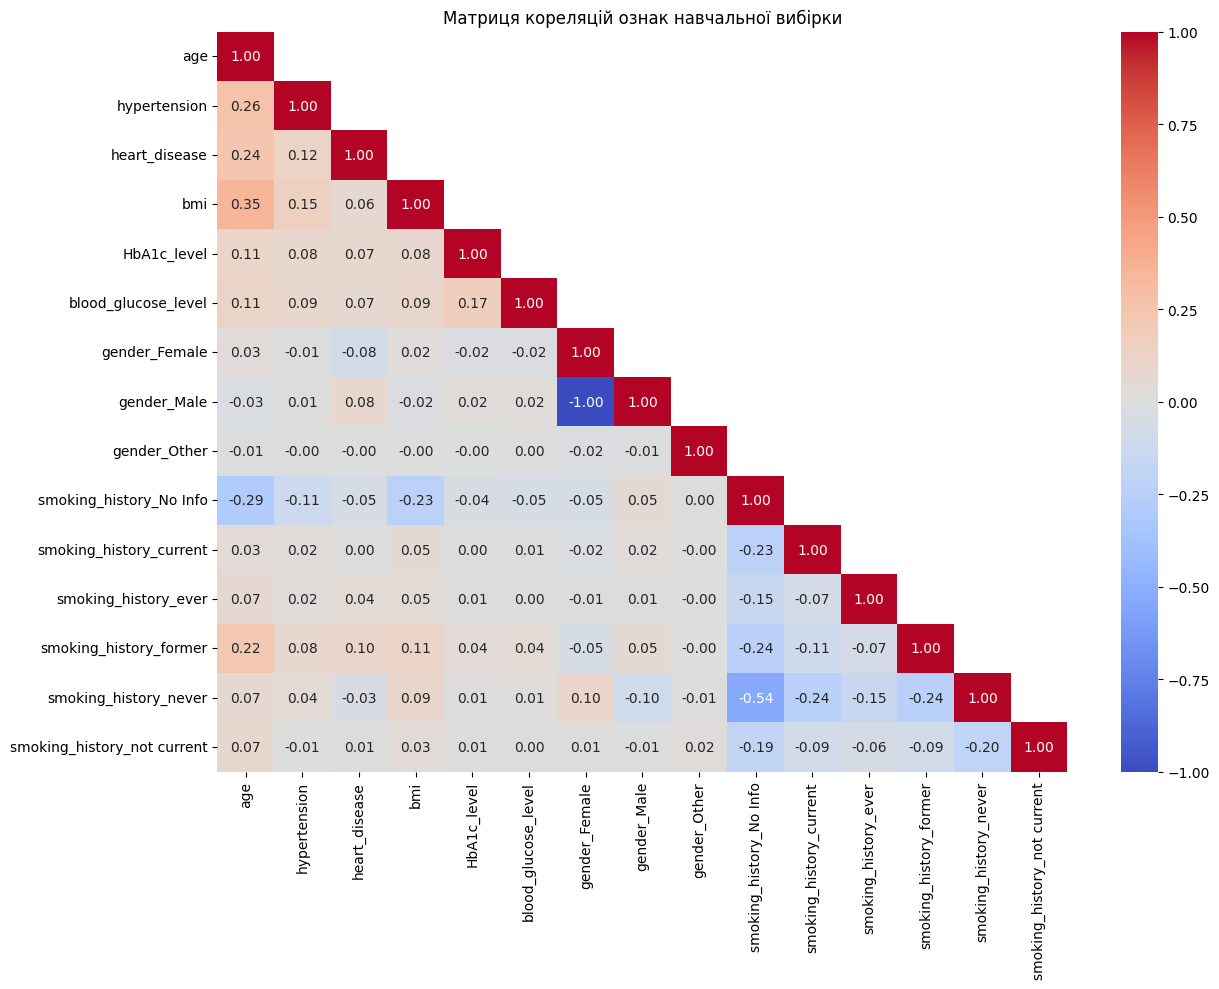

In [23]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).

corr_matrix = X_train.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype = bool), k = 1)

plt.figure(figsize = (13, 10))
sns.heatmap(corr_matrix, mask = mask, annot = True, fmt = '.2f',
            cmap = 'coolwarm', vmin = -1, vmax = 1)

plt.title('Матриця кореляцій ознак навчальної вибірки')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою методу `corr()` обчислимо матрицю кореляцій між усіма 15 ознаками навчальної вибірки `X_train`.

Для візуалізації отриманих коефіцієнтів побудуємо теплову карту за допомогою функції `sns.heatmap()`.

Для відображення числових значень використаємо параметр `annot=True`, а для встановлення колірної палітри – `cmap='coolwarm'`.

Для уникнення дублювання коефіцієнтів кореляції за допомогою функції `np.triu()` створимо маску верхнього трикутника матриці та відобразимо лише нижній трикутник разом із головною діагоналлю.

У результаті отримали теплову карту, яка дозволяє оцінити силу та напрямок лінійних зв'язків між ознаками.

Найсильніша від'ємна кореляція спостерігається між ознаками `gender_Female` та `gender_Male` (приблизно −1,00).

Це пояснюється тим, що вони утворені в результаті кодування однієї категоріальної змінної `gender` і для переважної більшості записів є взаємовиключними.

Також помітний від'ємний зв'язок між категоріями `smoking_history_No Info` та `smoking_history_never` (−0,54), що пов'язано з особливостями кодування категоріальної змінної `smoking_history`.

Серед початкових числових ознак найбільша кореляція спостерігається між `age` та `bmi` (0,35), проте вона не є сильною.

Інші числові ознаки мають переважно слабкі лінійні зв'язки між собою.

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

###**Висновок:**

У результаті кореляційного аналізу встановлено, що найбільший додатний зв'язок із цільовою змінною `diabetes` мають ознаки `blood_glucose_level` (0,423) та `HbA1c_level` (0,405), тоді як інші ознаки характеризуються слабшими кореляційними зв'язками.

Під час аналізу теплової карти виявлено дуже сильну від'ємну кореляцію між ознаками `gender_Female` та `gender_Male` (−1,00), а також помітну від'ємну кореляцію між `smoking_history_No Info` та `smoking_history_never` (−0,54).

Це пояснюється тим, що відповідні ознаки утворені в результаті кодування категоріальних змінних і є взаємовиключними.

Серед початкових числових ознак сильних кореляцій не виявлено, а найбільший зв'язок спостерігається між `age` та `bmi` (0,35).

Отже, на даному етапі видаляти ознаки не будемо, оскільки більшість із них не мають сильних кореляцій між собою, а високі від'ємні кореляції між окремими бінарними стовпцями зумовлені особливостями кодування категоріальних змінних.

Вплив таких залежностей можна враховувати під час подальшого навчання моделей із регуляризацією. Усі обчислення виконано виключно на навчальній вибірці, без використання тестових даних.

Перевірити викиди **лише на навчальній вибірці**

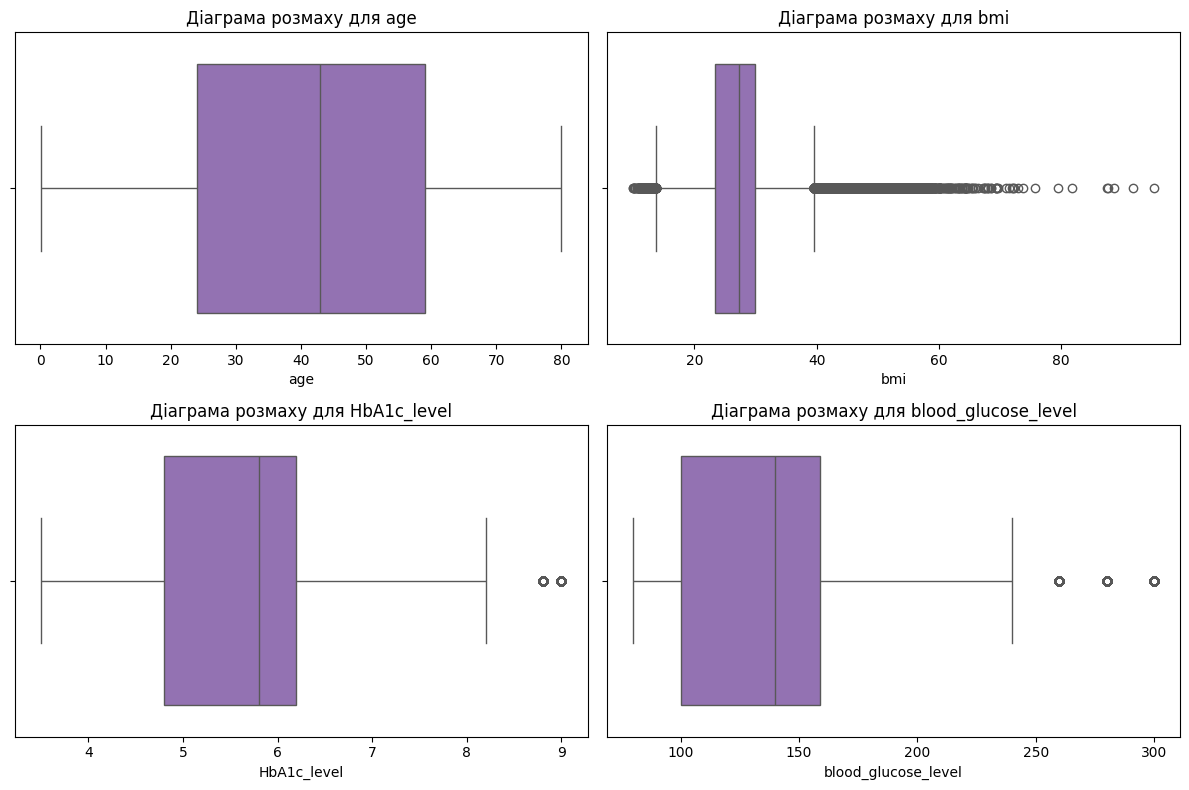

In [24]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.

continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

plt.figure(figsize = (12, 8))

for i, col in enumerate(continuous_cols):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(x = X_train[col], color = 'tab:purple')
    plt.title(f'Діаграма розмаху для {col}')
    plt.xlabel(col)

plt.tight_layout()
plt.show()

###**Пояснення:**

Для перевірки наявності викидів у навчальній вибірці `X_train` побудуємо діаграми розмаху (`boxplot`) для неперервних числових ознак `age`, `bmi`, `HbA1c_level` та `blood_glucose_level`.

Назви відповідних ознак збережемо у списку `continuous_cols`.

За допомогою циклу `for` та функції `sns.boxplot()` послідовно побудуємо горизонтальні діаграми розмаху для кожної ознаки.

Для розміщення чотирьох графіків в одній області використаємо функцію `plt.subplot()`, а для їх оформлення – `plt.title()` та `plt.xlabel()`.

Побудовані діаграми дозволять оцінити розподіл значень числових ознак, визначити медіану, квартилі та виявити потенційні викиди, які відображаються окремими точками за межами «вусів».

Для ознаки `age` викидів не виявлено, оскільки всі значення перебувають у межах «вусів» діаграми.

Для ознаки `bmi` спостерігається найбільша кількість потенційних викидів. Вони присутні як серед низьких, так і серед високих значень, причому найбільше – у верхній частині розподілу.

Для ознаки `HbA1c_level` виявлено окремі високі значення, які виходять за верхню межу діаграми розмаху.

Для ознаки `blood_glucose_level` також спостерігаються високі значення, які виходять за верхню межу «вусів».

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

###**Висновок:**

У результаті аналізу діаграм розмаху встановлено, що для ознаки age викидів не виявлено, тоді як для ознак `bmi`, `HbA1c_level` та `blood_glucose_level` спостерігаються значення, які виходять за межі «вусів» діаграм.

Найбільшу кількість потенційних викидів виявлено для ознаки `bmi`, особливо серед її високих значень.

Для ознак `HbA1c_level` та `blood_glucose_level` викиди представлені окремими високими значеннями відповідних медичних показників.

Виявлені викиди автоматично видаляти не будемо, оскільки екстремальні значення індексу маси тіла, рівня глікованого гемоглобіну та глюкози в крові можуть містити важливу інформацію для прогнозування наявності цукрового діабету.

Усі дослідження виконано виключно на навчальній вибірці `X_train`, без використання тестових даних.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [25]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Q1 = X_train['bmi'].quantile(0.25)
Q3 = X_train['bmi'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Перший квартиль (Q1):", Q1)
print("Третій квартиль (Q3):", Q3)
print("Міжквартильний розмах (IQR):", IQR)
print("Нижня межа:", lower_bound)
print("Верхня межа:", upper_bound)

Перший квартиль (Q1): 23.39
Третій квартиль (Q3): 29.85
Міжквартильний розмах (IQR): 6.460000000000001
Нижня межа: 13.7
Верхня межа: 39.540000000000006


###**Пояснення:**

Для дослідження потенційних викидів за методом міжквартильного розмаху (`IQR`) обчислимо відповідні межі для ознаки `bmi` виключно на навчальній вибірці `X_train`.

За допомогою методу `quantile()` визначимо перший (`Q1`) та третій (`Q3`) квартилі, після чого обчислимо міжквартильний розмах (`IQR`) як різницю між ними.

Далі визначимо нижню (`lower_bound`) та верхню (`upper_bound`) межі потенційних викидів, віднімаючи та додаючи до відповідних квартилів значення `1.5 * IQR`.

Значення індексу маси тіла (`bmi`), які є меншими за 13,70 або більшими за 39,54, визначаються як потенційні викиди за методом `IQR`.

Отримані межі підтверджують результати попереднього аналізу діаграм розмаху, на яких спостерігалися значення `bmi`, що виходять за межі «вусів».

Перевірити асиметрію розподілів ознак **на train**

In [26]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].

print("Асиметрія розподілів числових ознак навчальної вибірки:")
X_train[continuous_cols].skew()

Асиметрія розподілів числових ознак навчальної вибірки:


,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


###**Пояснення:**

За допомогою методу `skew()` обчислимо коефіцієнти асиметрії розподілів неперервних числових ознак навчальної вибірки `X_train`.

Для цього використаємо список `continuous_cols`, який містить ознаки `age`, `bmi`, `HbA1c_level` та `blood_glucose_level`.

Отримані результати свідчать про те, що ознаки `age` та `HbA1c_level` мають коефіцієнти асиметрії, близькі до нуля, тобто їхні розподіли є приблизно симетричними.

Для ознаки `bmi` спостерігається виражена додатна асиметрія (1,005), а для `blood_glucose_level` – помітна правостороння асиметрія (0,831), що свідчить про наявність довшого правого хвоста розподілу.

Найбільшу асиметрію серед досліджених числових ознак має `bmi`, що узгоджується з результатами попереднього аналізу діаграм розмаху, на яких було виявлено значну кількість високих значень індексу маси тіла.

При цьому всі обчислення виконано виключно на навчальній вибірці.

In [27]:
# TODO: перевірте пропуски окремо в X_train та X_test.

print("Пропущені значення у навчальній вибірці:")
display(X_train.isnull().sum())

print("\nПропущені значення у тестовій вибірці:")
display(X_test.isnull().sum())

Пропущені значення у навчальній вибірці:


,0
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0



Пропущені значення у тестовій вибірці:


,0
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


###**Пояснення:**

За допомогою методів `isnull()` та `sum()` повторно перевіримо наявність пропущених значень окремо в навчальній `X_train` та тестовій `X_test` вибірках.

У результаті встановлено, що всі 15 стовпців навчальної та тестової вибірок містять 0 пропущених значень.

Отже, після розбиття датасету та кодування категоріальних змінних пропуски `NaN` у даних відсутні.

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

###**Проміжний висновок:**

У результаті попереднього аналізу датасету встановлено наявність значного дисбалансу класів цільової змінної `diabetes`: після видалення дублікатів 91,18% записів належать до класу 0 (діабет відсутній), а 8,82% – до класу 1 (діабет наявний).

Для збереження приблизного співвідношення класів навчальну та тестову вибірки сформовано методом стратифікованого розбиття у пропорції 80/20.

За результатами кореляційного аналізу навчальної вибірки встановлено, що найбільший додатний зв'язок із цільовою змінною мають ознаки `blood_glucose_level` (0,423) та `HbA1c_level` (0,405).

Серед початкових числових ознак сильних кореляцій не виявлено, а високі від'ємні кореляції між окремими категоріальними ознаками пояснюються особливостями їх кодування.

Тому на даному етапі вирішено не видаляти жодної з ознак.

Під час дослідження діаграм розмаху встановлено, що для ознаки `age` викидів не виявлено, тоді як для `bmi`, `HbA1c_level` та `blood_glucose_level` спостерігаються потенційні викиди.

Найбільша кількість таких значень характерна для `bmi`.

Аналіз асиметрії також показав, що ознаки `bmi` (1,005) та `blood_glucose_level` (0,831) мають правосторонню асиметрію розподілу.

Виявлені викиди видаляти не будемо, оскільки екстремальні значення медичних показників можуть містити важливу інформацію для прогнозування наявності цукрового діабету.

Також підтверджено відсутність пропущених значень у навчальній і тестовій вибірках.

Усі дослідження кореляцій, меж `IQR` та асиметрії виконано виключно на навчальних даних, а тестову вибірку залишено незмінною для подальшого оцінювання моделей класифікації.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [28]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Розмір навчальної вибірки:", X_train_scaled.shape)
print("Розмір тестової вибірки:", X_test_scaled.shape)

Розмір навчальної вибірки: (76916, 15)
Розмір тестової вибірки: (19230, 15)


###**Пояснення:**

За допомогою класу `StandardScaler` виконаємо стандартизацію ознак навчальної та тестової вибірок, щоб привести їхні значення до порівнюваного масштабу.

Для цього створимо об'єкт `scaler` та застосуємо метод `fit_transform()` до навчальної вибірки `X_train`, який обчислить середні значення та стандартні відхилення ознак і виконає їх стандартизацію.

Далі за допомогою методу `transform()` стандартизуємо тестову вибірку `X_test`, використовуючи параметри, визначені виключно на навчальних даних.

Отримані масштабовані вибірки збережемо у змінних `X_train_scaled` та `X_test_scaled`.

У результаті стандартизації ознаки навчальної та тестової вибірок приведено до порівнюваного масштабу без зміни кількості записів і стовпців.

Застосування методу `fit_transform()` лише до навчальної вибірки та `transform()` до тестової дозволило уникнути витоку інформації з тестових даних під час масштабування.

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [29]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.

smote = SMOTE(random_state = 42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Розподіл класів до балансування:")
display(y_train.value_counts())

print("\nРозподіл класів після балансування:")
display(y_train_smote.value_counts())

Розподіл класів до балансування:


,count
diabetes,
0,70130
1,6786



Розподіл класів після балансування:


,count
diabetes,
0,70130
1,70130


###**Пояснення:**

Для усунення дисбалансу класів навчальної вибірки використаємо метод `SMOTE`, який дозволяє збільшити кількість записів меншості класу шляхом створення синтетичних прикладів на основі наявних спостережень.

Створимо об'єкт `smote` із параметром `random_state=42` для забезпечення відтворюваності результатів.

Далі за допомогою методу `fit_resample()` виконаємо балансування стандартизованої навчальної вибірки `X_train_scaled` та відповідної цільової змінної `y_train`.

Отримані збалансовані дані збережемо у змінних `X_train_smote` та `y_train_smote`.

Для перевірки результатів за допомогою методу `value_counts()` порівняємо кількість записів кожного класу до та після застосування `SMOTE`.

У результаті встановлено, що до балансування навчальна вибірка містила 70 130 записів класу 0 та 6 786 записів класу 1, що свідчило про значний дисбаланс.

Після застосування методу `SMOTE` кількість записів меншості класу 1 збільшилася з 6 786 до 70 130 шляхом створення 63 344 синтетичних прикладів. Кількість записів класу 0 залишилася незмінною.

Отже, загальна кількість навчальних прикладів збільшилася з 76 916 до 140 260, а співвідношення класів стало рівномірним - 50% на 50%.

Оголошуємо моделі

In [30]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.

models = {
    'LogisticRegression': LogisticRegression(random_state = 42, max_iter = 1000),
    'RidgeClassifier': RidgeClassifier(),
    'SGDClassifier': SGDClassifier(random_state = 42),
    'SVC': SVC(random_state = 42)
}

print("Створені моделі класифікації:")
for name in models:
    print(name)

Створені моделі класифікації:
LogisticRegression
RidgeClassifier
SGDClassifier
SVC


###**Пояснення:**

Створимо словник `models`, який міститиме чотири моделі класифікації: `LogisticRegression`, `RidgeClassifier`, `SGDClassifier` та `SVC`.

Для забезпечення відтворюваності результатів використаємо параметр `random_state=42` у моделях, для яких це передбачено.

Для логістичної регресії додатково встановимо параметр `max_iter=1000`, який визначатиме максимальну кількість ітерацій навчання моделі.

Далі за допомогою циклу `for` послідовно переберемо елементи словника `models` та виведемо назви створених моделей класифікації для перевірки правильності їх оголошення.

У результаті отримали чотири моделі: `LogisticRegression`, `RidgeClassifier`, `SGDClassifier` та `SVC`, які використовуватимемо для подальшого навчання та прогнозування наявності цукрового діабету.

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


###**1. LogisticRegression**

Класифікаційний звіт для LogisticRegression:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



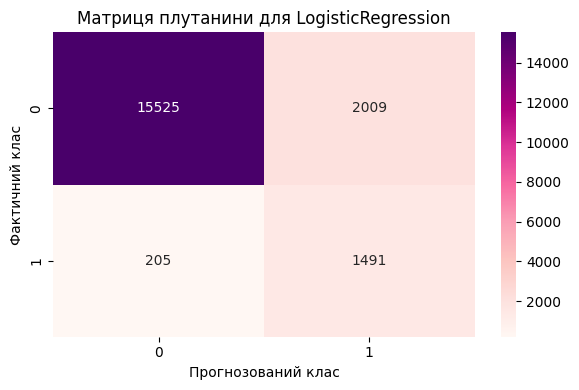

In [31]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).

model_lr = models['LogisticRegression']
model_lr.fit(X_train_smote, y_train_smote)

y_pred_lr = model_lr.predict(X_test_scaled)

print("Класифікаційний звіт для LogisticRegression:")
print(classification_report(y_test, y_pred_lr))

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize = (6, 4))
sns.heatmap(cm_lr, annot = True, fmt = 'd', cmap = 'RdPu',
            xticklabels = [0, 1], yticklabels = [0, 1])

plt.title('Матриця плутанини для LogisticRegression')
plt.xlabel('Прогнозований клас')
plt.ylabel('Фактичний клас')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою методу `fit()` виконаємо навчання моделі `LogisticRegression` на збалансованій навчальній вибірці `X_train_smote` та `y_train_smote`.

Далі за допомогою методу `predict()` отримаємо прогнози для масштабованої тестової вибірки `X_test_scaled`.

Для оцінювання якості моделі використаємо функцію `classification_report()`, а для аналізу правильних та помилкових прогнозів побудуємо матрицю плутанини за допомогою `confusion_matrix()` та `sns.heatmap()`.

У результаті отримали загальну точність класифікації (`accuracy`) 0,88 (88%).

Для класу 1 (діабет наявний) значення `precision` становить 0,43, `recall` – 0,88, а `f1-score` – 0,57.

Аналіз матриці плутанини показав, що модель правильно визначила 15 525 пацієнтів без діабету та 1 491 пацієнта з діабетом.

Водночас 2 009 пацієнтів без діабету було помилково віднесено до класу 1, а 205 пацієнтів із діабетом – до класу 0.

Отже, модель має досить високу здатність виявляти пацієнтів із діабетом, проте допускає значну кількість хибнопозитивних прогнозів.

###**2. RidgeClassifier**

Класифікаційний звіт для RidgeClassifier:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



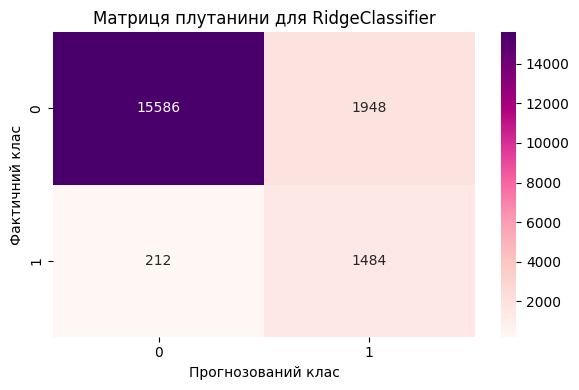

In [32]:
model_ridge = models['RidgeClassifier']
model_ridge.fit(X_train_smote, y_train_smote)

y_pred_ridge = model_ridge.predict(X_test_scaled)

print("Класифікаційний звіт для RidgeClassifier:")
print(classification_report(y_test, y_pred_ridge))

cm_ridge = confusion_matrix(y_test, y_pred_ridge)

plt.figure(figsize = (6, 4))
sns.heatmap(cm_ridge, annot = True, fmt = 'd', cmap = 'RdPu',
            xticklabels = [0, 1], yticklabels = [0, 1])

plt.title('Матриця плутанини для RidgeClassifier')
plt.xlabel('Прогнозований клас')
plt.ylabel('Фактичний клас')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою методу `fit()` виконаємо навчання моделі `RidgeClassifier` на збалансованій навчальній вибірці.

Далі сформуємо прогнози для тестових даних та оцінимо результати за допомогою класифікаційного звіту й матриці плутанини.

У результаті отримали загальну точність класифікації (`accuracy`) 0,89 (89%).

Для класу 1 значення `precision` становить 0,43, `recall` – 0,88, а `f1-score` – 0,58.

За матрицею плутанини встановлено, що модель правильно визначила 15 586 пацієнтів без діабету та 1 484 пацієнтів із діабетом.

При цьому 1 948 пацієнтів без діабету було помилково віднесено до класу 1, а 212 пацієнтів із діабетом – до класу 0.

Отже, модель `RidgeClassifier` продемонструвала дещо вищу загальну точність порівняно з `LogisticRegression`, проте також характеризується значною кількістю хибнопозитивних прогнозів.

###**3. SGDClassifier**

Класифікаційний звіт для SGDClassifier:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.54      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



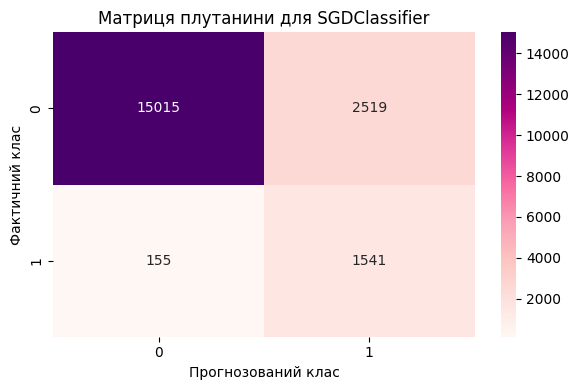

In [33]:
model_sgd = models['SGDClassifier']
model_sgd.fit(X_train_smote, y_train_smote)

y_pred_sgd = model_sgd.predict(X_test_scaled)

print("Класифікаційний звіт для SGDClassifier:")
print(classification_report(y_test, y_pred_sgd))

cm_sgd = confusion_matrix(y_test, y_pred_sgd)

plt.figure(figsize = (6, 4))
sns.heatmap(cm_sgd, annot = True, fmt = 'd', cmap = 'RdPu',
            xticklabels = [0, 1], yticklabels = [0, 1])

plt.title('Матриця плутанини для SGDClassifier')
plt.xlabel('Прогнозований клас')
plt.ylabel('Фактичний клас')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою методу `fit()` виконаємо навчання моделі `SGDClassifier` на збалансованій навчальній вибірці.

Після цього отримаємо прогнози для тестових даних та проаналізуємо класифікаційний звіт і матрицю плутанини.

У результаті отримали загальну точність класифікації (`accuracy`) 0,86 (86%).

Для класу 1 значення `precision` становить 0,38, `recall` – 0,91, а `f1-score` – 0,54.

Аналіз матриці плутанини показав, що модель правильно визначила 15 015 пацієнтів без діабету та 1 541 пацієнта з діабетом.

Водночас 2 519 пацієнтів без діабету було помилково віднесено до класу 1, а 155 пацієнтів із діабетом – до класу 0.

Отже, модель `SGDClassifier` продемонструвала найвищу здатність виявляти пацієнтів із діабетом за кількістю правильно визначених випадків, проте має найнижчу загальну точність та найбільшу кількість хибнопозитивних прогнозів серед досліджених моделей.

###**4. SVC**

Класифікаційний звіт для SVC:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



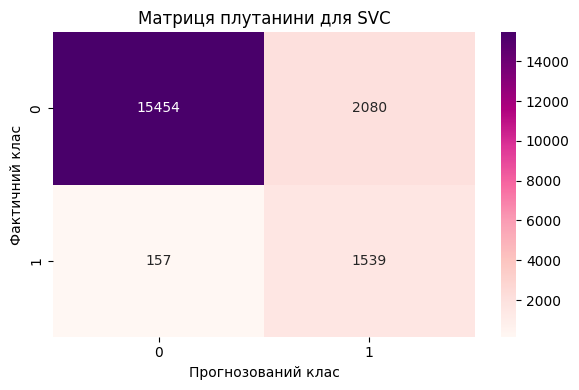

In [34]:
model_svc = models['SVC']
model_svc.fit(X_train_smote, y_train_smote)

y_pred_svc = model_svc.predict(X_test_scaled)

print("Класифікаційний звіт для SVC:")
print(classification_report(y_test, y_pred_svc))

cm_svc = confusion_matrix(y_test, y_pred_svc)

plt.figure(figsize = (6, 4))
sns.heatmap(cm_svc, annot = True, fmt = 'd', cmap = 'RdPu',
            xticklabels = [0, 1], yticklabels = [0, 1])

plt.title('Матриця плутанини для SVC')
plt.xlabel('Прогнозований клас')
plt.ylabel('Фактичний клас')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою методу `fit()` виконаємо навчання моделі `SVC` на збалансованій навчальній вибірці.

Далі за допомогою методу `predict()` отримаємо прогнози для тестових даних та оцінимо якість класифікації.

У результаті отримали загальну точність класифікації (`accuracy`) 0,88 (88%).`

Для класу 1 значення `precision` становить 0,43, `recall` – 0,91, а `f1-score` – 0,58.

За результатами матриці плутанини встановлено, що модель правильно визначила 15 454 пацієнтів без діабету та 1 539 пацієнтів із діабетом.

Водночас 2 080 пацієнтів без діабету було помилково віднесено до класу 1, а 157 пацієнтів із діабетом – до класу 0.

Отже, модель `SVC` продемонструвала високу здатність виявляти пацієнтів із діабетом та забезпечила кращий баланс між кількістю пропущених випадків діабету й хибнопозитивних прогнозів порівняно із `SGDClassifier`.

Оптимізувати гіперпараметри


In [35]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.

param_grids = {
    'LogisticRegression': {
        'C': [0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear']
    },

    'RidgeClassifier': {
        'alpha': [0.1, 1, 10]
    },

    'SGDClassifier': {
        'loss': ['hinge', 'log_loss'],
        'penalty': ['l2', 'l1']
    },

    'SVC': {
        'C': [0.1, 1],
        'kernel': ['linear', 'rbf']
    }
}

for name, params in param_grids.items():
    print(f"\nГіперпараметри для {name}:")
    print(params)


Гіперпараметри для LogisticRegression:
{'C': [0.1, 1, 10], 'solver': ['lbfgs', 'liblinear']}

Гіперпараметри для RidgeClassifier:
{'alpha': [0.1, 1, 10]}

Гіперпараметри для SGDClassifier:
{'loss': ['hinge', 'log_loss'], 'penalty': ['l2', 'l1']}

Гіперпараметри для SVC:
{'C': [0.1, 1], 'kernel': ['linear', 'rbf']}


###**Пояснення:**

Створимо словник `param_grids`, у якому визначимо набори гіперпараметрів та їхніх можливих значень для чотирьох моделей класифікації.

Для `LogisticRegression` досліджуватимемо параметри `C` та `solver`, для `RidgeClassifier` – `alpha`, для `SGDClassifier` – `loss` і `penalty`, а для `SVC` – `C` та `kernel`.

За допомогою циклу `for` виведемо сформовані набори параметрів для перевірки правильності створення словника.

Отримані набори використаємо для подальшого автоматизованого підбору оптимальних гіперпараметрів методом `HalvingGridSearchCV` із трикратною кросвалідацією.

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [36]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

###**Пояснення:**

Імпортуємо необхідні компоненти для автоматизованого підбору гіперпараметрів моделей класифікації.

Клас `HalvingGridSearchCV` використаємо для пошуку оптимальних комбінацій параметрів із поступовим відбором найкращих конфігурацій.

Клас `Pipeline` із бібліотеки `imblearn` дозволить об'єднати стандартизацію ознак, балансування класів методом `SMOTE` та навчання моделі в єдиний конвеєр.

In [37]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.

best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"\nОптимізація моделі: {name}")

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state = 42)),
        ('model', model)
    ])

    params = {
        f'model__{key}': values
        for key, values in param_grids[name].items()
    }

    search = HalvingGridSearchCV(
        estimator = pipeline,
        param_grid = params,
        cv = 3,
        scoring = 'f1',
        min_resources = 300,
        random_state = 42
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print("Оптимальні гіперпараметри:", search.best_params_)
    print(f"Найкращий F1-score (CV): {search.best_score_:.4f}")

    y_pred = search.best_estimator_.predict(X_test)

    print("\nКласифікаційний звіт після оптимізації:")
    print(classification_report(y_test, y_pred))


Оптимізація моделі: LogisticRegression
Оптимальні гіперпараметри: {'model__C': 1, 'model__solver': 'lbfgs'}
Найкращий F1-score (CV): 0.6098

Класифікаційний звіт після оптимізації:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230


Оптимізація моделі: RidgeClassifier
Оптимальні гіперпараметри: {'model__alpha': 10}
Найкращий F1-score (CV): 0.6516

Класифікаційний звіт після оптимізації:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230


Оптим

###**Пояснення:**

Для оптимізації гіперпараметрів чотирьох моделей класифікації використаємо метод `HalvingGridSearchCV` із трикратною кросвалідацією (`cv=3`).

Створимо словники `best_models` та `best_scores` для збереження найкращих моделей і відповідних значень метрики `F1-score`.

За допомогою циклу `for` послідовно переберемо моделі зі словника `models`.

Для кожної моделі створимо конвеєр `Pipeline`, який міститиме стандартизацію ознак за допомогою `StandardScaler`, балансування класів методом `SMOTE` та відповідний класифікатор.

Далі сформуємо набір гіперпараметрів на основі раніше створеного словника `param_grids`, додаючи префікс `model__` для їх використання всередині конвеєра.

Для підбору оптимальних параметрів створимо об'єкт `HalvingGridSearchCV` із параметрами `cv=3`, `scoring='f1'` та `min_resources=300`.

За допомогою методу `fit()` виконаємо пошук оптимальних гіперпараметрів виключно на навчальній вибірці `X_train` та `y_train`.

Після завершення оптимізації за допомогою атрибутів `best_params_` та `best_score_` виведемо найкращі комбінації гіперпараметрів і відповідні значення `F1-score`, отримані під час кросвалідації.

Найкращі моделі збережемо у словнику `best_models`, а їхні оцінки – у `best_scores`.

Далі за допомогою методу `predict()` отримаємо прогнози для тестової вибірки `X_test` та сформуємо класифікаційні звіти за допомогою функції `classification_report()`.

У результаті оптимізації гіперпараметрів чотирьох моделей класифікації методом `HalvingGridSearchCV` із трикратною кросвалідацією визначено найкращі комбінації параметрів для `LogisticRegression`, `RidgeClassifier`, `SGDClassifier` та `SVC`.

Для оцінювання якості моделей під час підбору параметрів використано метрику `F1-score`.

Найвище значення `F1-score` за результатами кросвалідації отримала модель `RidgeClassifier` (0,6516) із параметром `alpha=10`.

Для `SGDClassifier` найкращими виявилися параметри `loss='log_loss'` та `penalty='l2'`, які забезпечили `F1-score` 0,6412.

Моделі `LogisticRegression` та `SVC` отримали значення 0,6098 та 0,6001 відповідно.

Порівняння результатів на тестовій вибірці показало, що найбільше покращення після оптимізації спостерігається для моделі `SGDClassifier`, у якої `F1-score` класу 1 збільшився з 0,54 до 0,57, а загальна точність класифікації – з 0,86 до 0,88.

Для `LogisticRegression` та `RidgeClassifier` показники залишилися практично незмінними, тоді як для `SVC` значення `F1-score` класу 1 незначно зменшилося.

Отже, найкращою моделлю за результатами кросвалідаційного підбору гіперпараметрів виявилася `RidgeClassifier`, яка також продемонструвала найвищу загальну точність на тестовій вибірці (0,89).

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [38]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.

best_model_name = max(best_scores, key = best_scores.get)

best_model = best_models[best_model_name]

print("Найкраща модель:", best_model_name)
print(f"F1-score (CV): {best_scores[best_model_name]:.4f}")

Найкраща модель: RidgeClassifier
F1-score (CV): 0.6516


###**Пояснення:**

За допомогою функції `max()` визначимо найкращу модель класифікації за найбільшим середнім значенням `F1-score`, отриманим під час кросвалідації.

Для цього використаємо словник `best_scores`, який містить результати оптимізації гіперпараметрів чотирьох моделей, та параметр `key=best_scores.get.`

Назву моделі з найвищим значенням `F1-score` збережемо у змінній `best_model_name`, після чого отримаємо відповідну навчену модель зі словника `best_models` та збережемо її у змінній `best_model`.

Для перевірки результатів виведемо назву вибраної моделі та її значення `F1-score`.

У результаті встановлено, що найкращою моделлю за результатами кросвалідації є `RidgeClassifier` із середнім значенням `F1-score` 0,6516.

In [39]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.

X_sample = X_test.sample(n = 10, random_state = 42)

y_true = y_test.loc[X_sample.index]

y_pred = best_model.predict(X_sample)

results = pd.DataFrame({
    'Індекс': X_sample.index,
    'Фактичний клас': y_true.values,
    'Прогнозований клас': y_pred
})

print("Результати прогнозування для 10 випадкових записів:")
display(results)

Результати прогнозування для 10 випадкових записів:


,Індекс,Фактичний клас,Прогнозований клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


###**Пояснення:**

За допомогою методу `sample()` випадковим чином виберемо 10 записів із тестової вибірки `X_test`, використовуючи параметри `n=10` та `random_state=42` для забезпечення відтворюваності результатів.

Далі за індексами вибраних записів отримаємо відповідні фактичні значення цільової змінної `y_test` та збережемо їх у змінній `y_true`.

За допомогою методу `predict()` найкращої моделі `best_model` сформуємо прогнози для вибраних тестових записів.

Для порівняння результатів створимо таблицю `results` за допомогою `pd.DataFrame()`, яка міститиме індекси записів, фактичні та прогнозовані класи.

У результаті порівняння середніх значень `F1-score`, отриманих під час кросвалідації, найкращою моделлю класифікації визначено `RidgeClassifier` із показником 0,6516.

Для перевірки її роботи випадковим чином вибрано 10 записів із тестової вибірки та виконано прогнозування цільової змінної `diabetes`.

Аналіз отриманих результатів показав, що модель правильно класифікувала 8 із 10 записів, тоді як у 2 випадках помилково передбачила наявність діабету.

Отже, на вибраних тестових записах модель продемонструвала точність 80%, проте для об'єктивного оцінювання її якості необхідно враховувати результати класифікації на всій тестовій вибірці, зокрема метрики `precision`, `recall`, `F1-score` та матрицю плутанини.

**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

###**Підсумкові висновки:**

**1) Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів на `train?`**

У результаті аналізу датасету встановлено наявність значного дисбалансу класів цільової змінної `diabetes`.

Після видалення дублікатів 87 664 записи (91,18%) належали до класу 0 (діабет відсутній), а 8 482 записи (8,82%) – до класу 1 (діабет наявний).

Для усунення дисбалансу навчальної вибірки було використано метод `SMOTE`, у результаті чого кількість записів кожного класу збільшено або збережено на рівні 70 130.

Кореляційний аналіз навчальної вибірки показав, що найбільший додатний зв'язок із цільовою змінною мають ознаки `blood_glucose_level` (0,423) та `HbA1c_level` (0,405).

Серед початкових числових ознак сильних кореляцій між собою не виявлено.

Під час перевірки діаграм розмаху встановлено, що для ознаки `age` викидів немає, тоді як для `bmi`, `HbA1c_level` та `blood_glucose_level` спостерігаються потенційні викиди.

Найбільшу кількість таких значень виявлено для `bmi`, що також підтверджується правосторонньою асиметрією її розподілу (1,005).

Виявлені викиди не видалялися, оскільки екстремальні значення медичних показників можуть містити важливу інформацію для прогнозування діабету.

**2) Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?**

У результаті навчання чотирьох моделей класифікації встановлено, що до оптимізації найвищі значення `F1-score` для класу 1 отримали `RidgeClassifier` та `SVC` (0,58).

Найвищі значення `recall` продемонстрували `SGDClassifier` та `SVC` (0,91), що свідчить про їхню здатність виявляти більшу частку пацієнтів із діабетом.

Після оптимізації гіперпараметрів найвищий `F1-score` для класу 1 на тестовій вибірці отримала модель `RidgeClassifier` (0,58), тоді як найбільше значення `recall` продемонструвала `SVC` (0,89).

За результатами трикратної кросвалідації найкращою моделлю обрано `RidgeClassifier` із середнім `F1-score` = 0,6516, оскільки вона показала найвищий результат серед чотирьох досліджених моделей за метрикою, використаною під час підбору гіперпараметрів.

**3) Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?**

За результатами оптимізації методом `HalvingGridSearchCV` отримано такі оптимальні гіперпараметри: для `LogisticRegression` – `C=1` та `solver='lbfgs'`, для `RidgeClassifier` – `alpha=10`, для `SGDClassifier` – `loss='log_loss'` та `penalty='l2'`, а для `SVC` – `C=0.1` та `kernel='linear'`.

Аналіз матриць плутанини початкових моделей показав, що всі класифікатори допускають як хибнопозитивні, так і хибнонегативні прогнози.

Для моделі `RidgeClassifier`, яка була обрана найкращою за кросвалідацією, до оптимізації зафіксовано 1 948 хибнопозитивних та 212 хибнонегативних прогнозів.

Найменшу кількість хибнонегативних прогнозів отримала модель `SGDClassifier` (155), проте вона мала найбільшу кількість хибнопозитивних прогнозів (2 519).

Отже, основною проблемою моделей є значна кількість хибнопозитивних результатів, коли пацієнтам без діабету помилково прогнозується його наявність.

Водночас хибнонегативні прогнози є особливо важливими, оскільки відповідають випадкам, коли модель не виявила наявний діабет.

**4) Навіщо відкладати тестові дані та виконувати масштабування й `SMOTE` тільки на `train?`**

Розбиття датасету на навчальну та тестову вибірки необхідне для об'єктивного оцінювання здатності моделей класифікації прогнозувати результати на нових даних, які не використовувалися під час навчання.

Стандартизацію ознак потрібно налаштовувати лише на навчальній вибірці за допомогою методу `fit_transform()`, а до тестової застосовувати метод `transform()` із уже визначеними параметрами.

Це дозволяє запобігти витоку інформації з тестових даних під час підготовки ознак.

Метод `SMOTE` також необхідно застосовувати лише до навчальної вибірки, оскільки балансування тестових даних змінює початкове співвідношення класів і може призвести до необ'єктивного оцінювання якості моделей.

Під час кросвалідації масштабування та `SMOTE` виконувалися всередині конвеєра `Pipeline` окремо для кожного навчального згину.

Таким чином, тестову вибірку залишено без змін, що дозволило оцінювати результати класифікації на незалежних даних і зменшити ризик витоку інформації та завищення показників якості моделей.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [40]:
%pip install -q xgboost lightgbm catboost

In [41]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

###**Пояснення:**

Імпортуємо необхідні класи `XGBClassifier`, `LGBMClassifier` та `CatBoostClassifier` для створення додаткових моделей класифікації на основі градієнтного бустингу.

Ці алгоритми використовують ансамблі дерев рішень, які послідовно навчаються для зменшення помилок прогнозування.

###**1. XGBoost**

Класифікаційний звіт для XGBoost:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.93      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



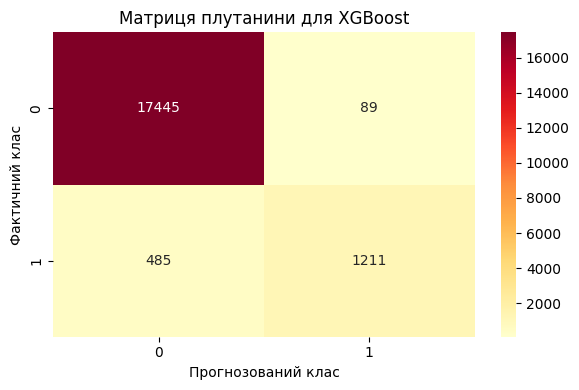

In [43]:
model_xgb = XGBClassifier(
    n_estimators = 200,
    max_depth = 5,
    learning_rate = 0.1,
    eval_metric = 'logloss',
    tree_method = 'hist',
    random_state = 42,
    n_jobs = 2
)

model_xgb.fit(X_train_smote, y_train_smote)

y_pred_xgb = model_xgb.predict(X_test_scaled)

print("Класифікаційний звіт для XGBoost:")
print(classification_report(y_test, y_pred_xgb))

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize = (6, 4))
sns.heatmap(cm_xgb, annot = True, fmt = 'd', cmap = 'YlOrRd',
            xticklabels = [0, 1], yticklabels = [0, 1])

plt.title('Матриця плутанини для XGBoost')
plt.xlabel('Прогнозований клас')
plt.ylabel('Фактичний клас')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою класу `XGBClassifier` створимо модель `XGBoost`, встановивши кількість дерев `n_estimators=200`, максимальну глибину `max_depth=5` та швидкість навчання `learning_rate=0.1`.

Для відтворюваності результатів використаємо параметр `random_state=42`, а для прискорення обчислень – `tree_method='hist'` та `n_jobs=2`.

За допомогою методу `fit()` виконаємо навчання моделі на збалансованій навчальній вибірці `X_train_smote` та `y_train_smote`.

Далі за допомогою методу `predict()` отримаємо прогнози для масштабованої тестової вибірки `X_test_scaled`.

Для оцінювання якості класифікації сформуємо звіт за допомогою `classification_report()` та побудуємо матрицю плутанини з використанням `confusion_matrix()` і `sns.heatmap()`.

У результаті отримали загальну точність класифікації (`Accuracy`) 0,9702 (97,02%).

Для класу 1 значення `Precision` становить 0,9315, `Recall` – 0,7140, а `F1-score` – 0,8084.

Аналіз матриці плутанини показав, що модель правильно визначила 17 445 пацієнтів без діабету та 1 211 пацієнтів із діабетом.

Водночас 89 пацієнтів без діабету було помилково віднесено до класу 1, а 485 пацієнтів із діабетом – до класу 0.

Модель `XGBoost` продемонструвала високу загальну точність класифікації та високу точність позитивних прогнозів.

Проте `Recall` для класу 1 становить лише 0,7140, тобто модель не виявила приблизно 28,6% фактичних випадків діабету.

###**2. LightGBM**

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Класифікаційний звіт для LightGBM:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.93      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



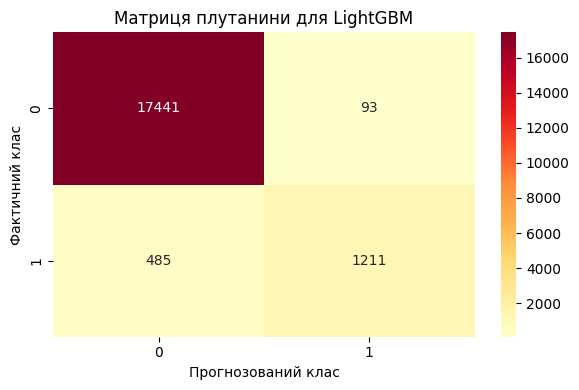

In [44]:
model_lgbm = LGBMClassifier(
    n_estimators = 200,
    max_depth = 5,
    learning_rate = 0.1,
    random_state = 42,
    verbosity = -1,
    n_jobs = 2
)

model_lgbm.fit(X_train_smote, y_train_smote)

y_pred_lgbm = model_lgbm.predict(X_test_scaled)

print("Класифікаційний звіт для LightGBM:")
print(classification_report(y_test, y_pred_lgbm))

cm_lgbm = confusion_matrix(y_test, y_pred_lgbm)

plt.figure(figsize = (6, 4))
sns.heatmap(cm_lgbm, annot = True, fmt = 'd', cmap = 'YlOrRd',
            xticklabels = [0, 1], yticklabels = [0, 1])

plt.title('Матриця плутанини для LightGBM')
plt.xlabel('Прогнозований клас')
plt.ylabel('Фактичний клас')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою класу `LGBMClassifier` створимо модель `LightGBM`, задавши кількість дерев `n_estimators=200`, максимальну глибину `max_depth=5` та швидкість навчання `learning_rate=0.1`.

Для відтворюваності результатів використаємо параметр `random_state=42`, а для вимкнення проміжних повідомлень – `verbosity=-1`.

Далі виконаємо навчання моделі на збалансованій навчальній вибірці та сформуємо прогнози для масштабованих тестових даних.

За допомогою функцій `classification_report()` та `confusion_matrix()` отримаємо класифікаційний звіт і матрицю плутанини.

У результаті отримали `Accuracy` 0,9699 (96,99%).

Для класу 1 значення `Precision` становить 0,9287, `Recall` – 0,7140, а `F1-score` – 0,8073.

Матриця плутанини показала, що модель правильно визначила 17 441 пацієнта без діабету та 1 211 пацієнтів із діабетом.

Водночас 93 пацієнтів без діабету було помилково віднесено до класу 1, а 485 пацієнтів із діабетом – до класу 0.

Модель `LightGBM` продемонструвала результати, дуже близькі до `XGBoost`, проте дещо поступилася їй за `Accuracy`, `Precision` та `F1-score`.

При цьому обидві моделі правильно визначили однакову кількість пацієнтів із діабетом.

###**3. CatBoost**

Класифікаційний звіт для CatBoost:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.95      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



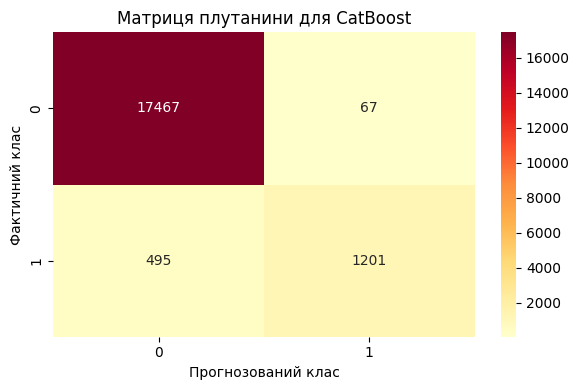

In [45]:
model_cat = CatBoostClassifier(
    iterations = 200,
    depth = 6,
    learning_rate = 0.1,
    random_seed = 42,
    thread_count = 2,
    verbose = False
)

model_cat.fit(X_train_smote, y_train_smote)

y_pred_cat = model_cat.predict(X_test_scaled)

print("Класифікаційний звіт для CatBoost:")
print(classification_report(y_test, y_pred_cat))

cm_cat = confusion_matrix(y_test, y_pred_cat)

plt.figure(figsize = (6, 4))
sns.heatmap(cm_cat, annot = True, fmt = 'd', cmap = 'YlOrRd',
            xticklabels = [0, 1], yticklabels = [0, 1])

plt.title('Матриця плутанини для CatBoost')
plt.xlabel('Прогнозований клас')
plt.ylabel('Фактичний клас')
plt.tight_layout()
plt.show()

###**Пояснення:**

За допомогою класу `CatBoostClassifier` створимо модель `CatBoost`, встановивши кількість ітерацій `iterations=200`, глибину дерев `depth=6` та швидкість навчання `learning_rate=0.1`.

Для забезпечення відтворюваності результатів використаємо параметр `random_seed=42`, а для вимкнення повідомлень під час навчання – `verbose=False`.

Далі за допомогою методу `fit()` навчимо модель на збалансованій навчальній вибірці, після чого отримаємо прогнози для тестових даних та оцінимо їх за допомогою класифікаційного звіту й матриці плутанини.

У результаті отримали `Accuracy` 0,9708 (97,08%).

Для класу 1 значення `Precision` становить 0,9472, `Recall` – 0,7081, а `F1-score` – 0,8104.

Аналіз матриці плутанини показав, що модель правильно визначила 17 467 пацієнтів без діабету та 1 201 пацієнта з діабетом.

Водночас 67 пацієнтів без діабету було помилково віднесено до класу 1, а 495 пацієнтів із діабетом – до класу 0.

Модель `CatBoost` продемонструвала найвищу загальну точність класифікації та найбільші значення `Precision` і `F1-score` для класу 1 серед трьох моделей.

Також вона допустила найменшу кількість хибнопозитивних прогнозів (67).

Проте за `Recall` модель дещо поступається `XGBoost` і `LightGBM`, оскільки пропустила більшу кількість фактичних випадків діабету.

###**Порівняння результатів трьох моделей**

In [46]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

predictions = {
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgbm,
    'CatBoost': y_pred_cat
}

comparison = []

for name, y_pred in predictions.items():
    comparison.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (1)': precision_score(y_test, y_pred),
        'Recall (1)': recall_score(y_test, y_pred),
        'F1-score (1)': f1_score(y_test, y_pred)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))

,Модель,Accuracy,Precision (1),Recall (1),F1-score (1)
0,XGBoost,0.9702,0.9315,0.7140,0.8084
1,LightGBM,0.9699,0.9287,0.7140,0.8073
2,CatBoost,0.9708,0.9472,0.7081,0.8104


###**Загальний висновок (моделі XGBoost, LightGBM та CatBoost):**

У результаті виконання додаткового завдання було реалізовано та досліджено три моделі класифікації на основі градієнтного бустингу: `XGBoost`, `LightGBM` та `CatBoost`.

Для кожної моделі виконано навчання на збалансованій навчальній вибірці, сформовано прогнози для тестових даних, отримано класифікаційні звіти та побудовано матриці плутанини.

За результатами оцінювання встановлено, що всі три моделі продемонстрували високу загальну точність класифікації на рівні приблизно 97%.

Найкращі показники `Accuracy` (0,9708), `Precision` (0,9472) та `F1-score` (0,8104) для класу 1 отримала модель `CatBoost`.

Водночас моделі `XGBoost` та `LightGBM` показали дещо вищі значення `Recall` (0,7140), що свідчить про їхню здатність виявляти більшу частку пацієнтів із діабетом.

Аналіз матриць плутанини показав, що найменшу кількість хибнопозитивних прогнозів допустила модель `CatBoost` (67), тоді як `XGBoost` та `LightGBM` – 89 і 93 відповідно. `

При цьому всі три моделі пропустили значну кількість фактичних випадків діабету: 485 для `XGBoost` і `LightGBM` та 495 для `CatBoost`.

Отже, найкращою моделлю за сукупністю показників `Accuracy`, `Precision` та `F1-score` виявилася `CatBoost`, проте для завдань, у яких особливо важливо мінімізувати кількість пропущених випадків діабету, доцільніше звертати увагу на моделі з вищим `Recall`.

Порівняно з раніше дослідженими лінійними класифікаторами моделі градієнтного бустингу забезпечили вищі `Precision` та `F1-score` для класу 1, але нижчий `Recall`, що свідчить про наявність компромісу між точністю позитивних прогнозів та здатністю виявляти всі випадки захворювання.